# Construction de la base finale : foncier, PIB et contours des communes


## Objectif de ce notebook

Compléter la base df_final (niveau de vie, APL, population, hôpitaux) avec :
- le **prix du foncier** (transactions DVF) ;
- le **PIB par habitant** (par région) ;
- les **contours des communes**, pour faire des cartes.


## Plan

1. Téléchargement des données
2. Prix du foncier (DVF)
3. PIB par habitant (régions)
4. Table des communes (contours)
5. Assemblage de la base finale
6. Cartes
7. Bilan 

## Données utilisées

| Fichier | Source | Contenu |
|---|---|---|
| `communes_2024_50m.geojson` | data.gouv.fr (contours administratifs) | contours des communes, arrondissements de Paris, Lyon et Marseille compris |
| `dvf_2025_france.csv.gz` | data.gouv.fr (demandes de valeurs foncières) | transactions immobilières (fichier 2025) |
| `pib_regions.xlsx` | Insee (PIB 2024, comparaisons régionales) | PIB et PIB par habitant par région |


## 1. Téléchargement des données

On télécharge les quatre fichiers une seule fois dans le dossier data/.
Si un fichier est déjà là, on ne le télécharge pas à nouveau .

### 1.1 Imports et dossier de travail

In [26]:
# Installation 
# %pip install mapclassify geopandas openpyxl

import os
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from matplotlib.colors import ListedColormap
from scipy.stats import spearmanr

# Dossier où on range les fichiers téléchargés
dossier = Path("data")
dossier.mkdir(exist_ok=True)

### 1.2 Téléchargement des fichiers

In [27]:
def telecharger(url, nom_fichier):
    """Télécharge un fichier et l'enregistre dans le dossier data/ (sauf s'il existe déjà)."""
    chemin = dossier / nom_fichier
    if chemin.exists():                      # inutile de le télécharger deux fois
        print("Déjà présent :", nom_fichier)
        return
    reponse = requests.get(url, timeout=300)
    reponse.raise_for_status()               # arrête le programme si le lien est cassé
    chemin.write_bytes(reponse.content)
    print("Téléchargé :", nom_fichier)

# Liste des fichiers : (adresse, nom sur mon ordinateur)
fichiers = [
    ("https://www.data.gouv.fr/api/1/datasets/r/54499806-3eae-4f3a-9475-d891d795e71d",
     "communes_2024_50m.geojson"),
    ("https://www.insee.fr/fr/statistiques/fichier/8217527/DS_BPE_CSV_FR.zip",
     "bpe.zip"),
    ("https://www.insee.fr/fr/statistiques/fichier/2012723/TCR_062.xlsx",
     "pib_regions.xlsx"),
    ("https://www.data.gouv.fr/api/1/datasets/r/b3a0c6d2-2a5a-45a3-81a8-9e860caf5e14",
     "dvf_2025_france.csv.gz"),
]

for url, nom in fichiers:
    telecharger(url, nom)

Déjà présent : communes_2024_50m.geojson
Déjà présent : bpe.zip
Déjà présent : pib_regions.xlsx
Déjà présent : dvf_2025_france.csv.gz


## 2. Prix du foncier (DVF)

La base DVF contient les ventes immobilières. On veut un **prix au m² médian par commune**.

On procède en cinq étapes : lecture, filtres, calcul du prix au m², regroupement des arrondissements, médianes.

**Limite :** DVF ne contient pas l'Alsace-Moselle (départements 57, 67 et 68). Ces communes n'auront pas de prix.

### 2.1 Lecture des colonnes utiles

In [28]:
# On lit seulement les colonnes dont on a besoin (le fichier est très gros)
colonnes = ["id_mutation", "nature_mutation", "valeur_fonciere", "code_commune",
            "code_departement", "type_local", "surface_reelle_bati"]

# Les codes sont lus en texte pour garder les zéros du début (ex : 01001)
dvf = pd.read_csv("data/dvf_2025_france.csv.gz", usecols=colonnes,
                  dtype={"code_commune": str, "code_departement": str})
print(len(dvf), "lignes lues")

3793113 lignes lues


### 2.2 Filtres

On garde uniquement des ventes de logements dont le prix et la surface sont exploitables.

In [29]:
# 1. On garde les ventes de logements (appartements et maisons)
dvf = dvf[dvf["nature_mutation"] == "Vente"]
dvf = dvf[dvf["type_local"].isin(["Appartement", "Maison"])]

# 2. On garde les surfaces et les prix positifs
dvf = dvf[(dvf["surface_reelle_bati"] > 0) & (dvf["valeur_fonciere"] > 0)]

# 3. On garde les ventes d'un seul logement (une seule ligne par id_mutation)
#    duplicated(keep=False) met True sur toutes les lignes en double, et ~ inverse le résultat
dvf = dvf[~dvf["id_mutation"].duplicated(keep=False)]

print(len(dvf), "ventes retenues")

757913 ventes retenues


### 2.3 Prix au m²

In [30]:
# Prix au m² = prix de vente / surface du bâti
dvf["prix_m2"] = dvf["valeur_fonciere"] / dvf["surface_reelle_bati"]
print(dvf["prix_m2"].describe().round(0))

# Filtre possible sur les prix aberrants (à décider en équipe, pas utilisé pour l'instant) :
# dvf = dvf[(dvf["prix_m2"] > 500) & (dvf["prix_m2"] < 30000)]

count     757913.0
mean        3335.0
std         6370.0
min            0.0
25%         1696.0
50%         2636.0
75%         3994.0
max      3210526.0
Name: prix_m2, dtype: float64


**Remarque :** le minimum est 0 et le maximum dépasse 3 millions d'euros le m². Ce sont des valeurs aberrantes (erreurs de saisie).
On utilise donc la **médiane** plutôt que la moyenne, car elle y est peu sensible.

### 2.4 Regroupement des arrondissements

Dans DVF, Paris, Lyon et Marseille sont codées par arrondissement. Le reste de la base est au niveau commune.
On crée donc un code « commune » qui regroupe les arrondissements, tout en gardant le code d'origine.

In [31]:
def regrouper(code):
    """Remplace le code d'un arrondissement par celui de sa ville (Paris, Lyon, Marseille)."""
    if code.startswith("751"):
        return "75056"      # Paris
    if code.startswith("6938"):
        return "69123"      # Lyon
    if code.startswith("132"):
        return "13055"      # Marseille
    return code             # les autres communes ne changent pas

dvf["code_com"] = dvf["code_commune"].apply(regrouper)

### 2.5 Médianes par zone

On calcule la médiane du prix au m² par arrondissement, par commune et par département, ainsi que le nombre de ventes par commune.

In [32]:
# Arrondissements : lignes dont le code a changé avec la fonction regrouper
arrondissements = dvf[dvf["code_commune"] != dvf["code_com"]]
prix_arr = arrondissements.groupby("code_commune")["prix_m2"].median()

# Communes (Paris, Lyon et Marseille comptées comme une seule commune)
prix_com = dvf.groupby("code_com")["prix_m2"].median()
nb_ventes = dvf.groupby("code_com").size()

# Départements
prix_dep = dvf.groupby("code_departement")["prix_m2"].median()

print(len(prix_arr), "arrondissements,", len(prix_com), "communes,", len(prix_dep), "départements")

45 arrondissements, 29264 communes, 97 départements


## 3. PIB par habitant (régions)

Le fichier de l'Insee utilisé ici donne le PIB par habitant **par région**.
Toutes les communes d'une même région auront donc la même valeur.

### 3.1 Lecture du fichier brut

On regarde d'abord le fichier tel quel, pour repérer où sont les données (il y a des lignes de titre au début).

In [33]:
pib_brut = pd.read_excel("data/pib_regions.xlsx", sheet_name="REG", header=None)
print(pib_brut.shape)
pib_brut.head(10)

(29, 8)


/tmp/ipykernel_56578/3152673503.py:1: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  pib_brut = pd.read_excel("data/pib_regions.xlsx", sheet_name="REG", header=None)


,0,1,2,3,4,5,6,7
0,Produit intérieur brut en 2024 : comparaisons ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,PIB (millions d'euros),NaN,PIB par habitant (euros),NaN,PIB par emploi (euros),NaN
4,NaN,NaN,2024,2023.0,2024,2023.0,2024,2023.0
5,84,Auvergne-Rhône-Alpes,346405,336643.0,41949,40944.0,92972,91017.0
6,27,Bourgogne-Franche-Comté,95775,93225.0,34216,33260.0,85490,83873.0
7,53,Bretagne,126549,122021.0,36552,35429.0,84226,81850.0
8,24,Centre-Val de Loire,91467,89691.0,35451,34750.0,87278,86274.0
9,94,Corse,13358,12733.0,37470,35970.0,91933,88243.0


### 3.2 Nettoyage

On garde trois colonnes : le code de la région, son nom et le PIB par habitant en 2024.

In [34]:
# Les données commencent à la ligne 5 ; colonnes 0 (code), 1 (nom) et 4 (PIB par habitant 2024)
pib_reg = pib_brut.iloc[5:, [0, 1, 4]].copy()
pib_reg.columns = ["code_region", "region", "pib_hab_2024"]

# Codes en texte (sans le ".0") et PIB en nombres
pib_reg["code_region"] = pib_reg["code_region"].astype(str).str.replace(".0", "", regex=False)
pib_reg["pib_hab_2024"] = pd.to_numeric(pib_reg["pib_hab_2024"], errors="coerce")
pib_reg = pib_reg.dropna(subset=["pib_hab_2024"])          # enlève les lignes vides

# Lignes de total à enlever : P (France métropolitaine hors Île-de-France),
# M (France métropolitaine) et F (France)
pib_reg = pib_reg[~pib_reg["code_region"].isin(["P", "M", "F"])]

# Dictionnaire : code région -> PIB par habitant
reg_pib = pib_reg.set_index("code_region")["pib_hab_2024"]
print(pib_reg.to_string())

   code_region                               region  pib_hab_2024
5           84                 Auvergne-Rhône-Alpes       41949.0
6           27              Bourgogne-Franche-Comté       34216.0
7           53                             Bretagne       36552.0
8           24                  Centre-Val de Loire       35451.0
9           94                                Corse       37470.0
10          44                            Grand Est       35431.0
11          32                      Hauts-de-France       32891.0
12          11                        Île-de-France       69514.0
13          28                            Normandie       35287.0
14          75                   Nouvelle-Aquitaine       36206.0
15          76                            Occitanie       35934.0
16          52                     Pays de la Loire       37541.0
17          93           Provence-Alpes-Côte d'Azur       41818.0
20          01  Guadeloupe (y compris Saint-Martin)       29099.0
21        

## 4. Table des communes (contours)

Le fichier de contours donne, pour chaque commune, son département et sa région.
On s'en sert pour créer une **table de passage** (pont) entre le code commune et le PIB de sa région.
Elle servira à compléter les communes dont la région manque dans df_final.

### 4.1 Lecture des contours

In [35]:
# Les contours sont gardés pour faire les cartes 
contours = gpd.read_file("data/communes_2024_50m.geojson")

# Version sans la géométrie : une simple table avec le code, le nom, le département et la région
table_communes = pd.DataFrame(contours.drop(columns="geometry"))
print(table_communes[["code", "nom", "departement", "region"]].head())

    code                      nom departement region
0  01001  L'Abergement-Clémenciat          01     84
1  01002    L'Abergement-de-Varey          01     84
2  01004        Ambérieu-en-Bugey          01     84
3  01005      Ambérieux-en-Dombes          01     84
4  01006                  Ambléon          01     84


### 4.2 Table de passage commune à PIB

In [36]:
pont = table_communes[["code", "departement", "region"]].copy()
pont["pib_hab"] = pont["region"].map(reg_pib)          # PIB de la région de chaque commune

# Contrôle : Marseille, Lyon, Paris et un arrondissement de Paris
print(pont["pib_hab"].isna().sum(), "communes sans PIB")
print(pont[pont["code"].isin(["75056", "75111", "69123", "13055"])])

111 communes sans PIB
        code departement region  pib_hab
4342   13055          13     93  41818.0
27098  69123          69     84  41949.0
29269  75056          75     11  69514.0
29280  75111          75     11  69514.0


In [37]:
# Quelles communes n'ont pas de PIB ?
sans = pont[pont["pib_hab"].isna()]
print(sans["region"].value_counts())

region
987    48
988    33
06     17
984     5
986     3
975     2
977     1
978     1
989     1
Name: count, dtype: int64


Le tableau de l’Insee ne contient que les 13 régions métropolitaines et 4 régions d’outre-mer (Guadeloupe, Martinique, Guyane, La Réunion). Mayotte et les collectivités d’outre-mer n’y figurent pas.

## 5. Assemblage de la base finale

On part de df_final (créée par fusion.py) et on lui ajoute le prix du foncier et le PIB.

### 5.1 Chargement de la base

In [38]:
# On lit tout en texte (dtype=str) pour ne pas perdre les zéros des codes ; on convertit plus bas
df_final = pd.read_excel("data/processed/df_final.xlsx", dtype=str)
print(df_final.shape)

/tmp/ipykernel_56578/2718795810.py:2: Pandas4Warning: The default engine for reading 'xlsx' files will change from 'openpyxl' to 'calamine' in a future version. Pass engine='openpyxl' (or set the 'io.excel.xlsx.reader' option) to keep the current engine and silence this warning.
  df_final = pd.read_excel("data/processed/df_final.xlsx", dtype=str)


(34768, 16)


### 5.2 Ajout du prix au m², du nombre de ventes et du PIB

In [39]:
# map() cherche, pour chaque commune, sa valeur dans le dictionnaire correspondant
df_final["prix_m2_median"] = df_final["COM_INSEE"].map(prix_com)
df_final["nb_ventes"] = df_final["COM_INSEE"].map(nb_ventes)
df_final["pib_hab"] = df_final["REG"].map(reg_pib)       # PIB de la région de la commune

# Contrôles
print(df_final.shape)
print(df_final[["prix_m2_median", "nb_ventes", "pib_hab"]].isna().sum())
print(df_final[df_final["COM_INSEE"].isin(["75056", "69123", "13055"])]
      [["COM_INSEE", "commune", "prix_m2_median", "pib_hab", "apl"]])

(34768, 19)
prix_m2_median    5585
nb_ventes         5585
pib_hab             34
dtype: int64
      COM_INSEE    commune  prix_m2_median  pib_hab                apl
4069      13055  Marseille     3313.839489  41818.0  5.201306138207334
27391     69123       Lyon     4471.428571  41949.0  4.600774702697755
29004     75056      Paris     9700.000000  69514.0  5.496621471353419


### 5.3 Compléter les PIB manquants

Quelques communes n'ont pas de région dans df_final : on cherche leur PIB avec la table de passage pont.

In [40]:
# Table de recherche : pour chaque code commune, le PIB par habitant de sa région
# (pont vient des contours 2024 ; set_index met le code en étiquette de ligne)
pib_par_commune = pont.set_index("code")["pib_hab"]

# les communes de df_final dont le PIB est vide
manque = df_final["pib_hab"].isna()

# Pour ces communes seulement :
#   - on prend leur code commune (COM_INSEE)
#   - map() cherche ce code dans pib_par_commune et renvoie le PIB trouvé
#   - on écrit le résultat dans la colonne pib_hab
# Les communes qui avaient déjà un PIB ne changent pas ;
# si un code n'est pas dans pont, le PIB reste vide (NaN)
df_final.loc[manque, "pib_hab"] = df_final.loc[manque, "COM_INSEE"].map(pib_par_commune)

print(df_final["pib_hab"].isna().sum(), "communes sans PIB")
print(df_final[df_final["pib_hab"].isna()][["COM_INSEE", "commune", "DEP", "REG"]])

4 communes sans PIB
    COM_INSEE commune  DEP  REG
615     15035     NaN  NaN  NaN
628     15047     NaN  NaN  NaN
638     15171     NaN  NaN  NaN
644     15031     NaN  NaN  NaN


4 communes du Cantal n’apparaissent ni dans le fichier APL ni dans les contours 2024 (probablement un changement de code).

### 5.4 Compléter les départements manquants

In [41]:
# Le département correspond aux deux premiers caractères du code commune (2A et 2B pour la Corse)
df_final["DEP"] = df_final["DEP"].fillna(df_final["COM_INSEE"].str[:2])

### 5.5 Colonnes en nombres

Comme la base a été lue en texte, on convertit les colonnes numériques.

In [42]:
colonnes_numeriques = ["apl", "apl65", "apl62", "apl60", "pop_std", "pop_tot",
                       "revenu_median", "prix_m2_median", "nb_ventes", "pib_hab", "nb_hopitaux"]

for col in colonnes_numeriques:
    if col in df_final.columns:
        # on remplace la virgule décimale par un point, puis on convertit
        df_final[col] = pd.to_numeric(
            df_final[col].astype(str).str.replace(",", ".", regex=False), errors="coerce")#on convertit en str pour remplacer 

# Ces deux colonnes valent toujours "COM" et "MED_SL" : on les supprime
df_final = df_final.drop(columns=["GEO_OBJECT", "FILOSOFI_MEASURE"], errors="ignore")

print(df_final.dtypes)

COM_INSEE             str
revenu_median     float64
commune               str
apl               float64
apl65             float64
apl62             float64
apl60             float64
pop_std           float64
pop_tot           float64
CODGEO                str
DEP                   str
REG                   str
ARR                   str
nb_hopitaux         int64
prix_m2_median    float64
nb_ventes         float64
pib_hab           float64
dtype: object


### 5.6 Contrôle des valeurs manquantes des variables

In [43]:
# Nombre de valeurs manquantes par colonne
df_final.isna().sum()

COM_INSEE            0
revenu_median     3974
commune             10
apl                 10
apl65               10
apl62               10
apl60               10
pop_std             10
pop_tot             10
CODGEO              13
DEP                  0
REG                 10
ARR                 10
nb_hopitaux          0
prix_m2_median    5585
nb_ventes         5585
pib_hab              4
dtype: int64

### 5.7 Enregistrement de la base

On l'enregistre en CSV 

In [44]:
df_final.to_csv("data/processed/df_final3.csv", index=False, encoding="utf-8-sig")
print("Base enregistrée :", df_final.shape)

Base enregistrée : (34768, 17)


## 6. Cartes

On associe la base aux contours des communes, puis on trace trois cartes : l'APL, le niveau de vie et le prix du foncier.

### 6.1 Jointure avec les contours

In [45]:
# Communes 
communes = contours[["code", "nom", "geometry"]].copy()
communes["code_com"] = communes["code"].apply(regrouper)   # un arrondissement (75101) prend le code de sa ville (75056)

d = df_final[~df_final["COM_INSEE"].str.startswith("97")]    # France métropolitaine seulement
gc = communes.merge(d, left_on="code_com", right_on="COM_INSEE", how="inner")

# Départements : on fusionne les communes d'un même département 
dep_geo = (contours[["departement", "geometry"]]
           .rename(columns={"departement": "DEP"})
           .dissolve(by="DEP").reset_index())

def moyenne_ponderee(df, col, poids):
    """Moyenne par département, pondérée (par la population)."""
    s = df.dropna(subset=[col, poids])
    return (s[col] * s[poids]).groupby(s["DEP"]).sum() / s.groupby("DEP")[poids].sum()

dep = pd.DataFrame({
    "apl": moyenne_ponderee(d, "apl", "pop_std"),
    "revenu_median": moyenne_ponderee(d, "revenu_median", "pop_tot"),
}).reset_index()
gdep = dep_geo.merge(dep, on="DEP")

# Noms des départements (si l'adresse ne répond pas, on garde le numéro)
try:
    noms_dep = {x["code"]: x["nom"] for x in
                requests.get("https://geo.api.gouv.fr/departements", timeout=30).json()}
except Exception:
    noms_dep = {}
gdep["nom"] = gdep["DEP"].map(noms_dep).fillna(gdep["DEP"])

# Classes de l'APL (les mêmes seuils pour les deux cartes)
bornes = [-0.01, 2.5, 4, np.inf]
noms = ["sous-dotée (≤ 2,5)", "moyennement dotée (2,5 à 4)", "bien dotée (> 4)"]
gc["classe_apl"] = pd.cut(gc["apl"], bornes, labels=noms)
gdep["classe_apl"] = pd.cut(gdep["apl"], bornes, labels=noms)

print(len(gdep), "départements")      

96 départements


### 6.2 Fonctions pour tracer les cartes

In [46]:
def enregistrer(fichier, dpi=200):
    """Enregistre la figure courante (crée le dossier si besoin)."""
    if fichier is None:
        return
    chemin = Path(fichier)
    chemin.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(chemin, dpi=dpi, bbox_inches="tight")

In [47]:
def cote_a_cote(col, titre, cmap, categorie=False, fichier=None):
    """Départements à gauche, communes à droite."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    for ax, gdf, nom in [(axes[0], gdep, "Départements"), (axes[1], gc, "Communes")]:
        if categorie:      # classes déjà faites (classes de l'APL)
            gdf.plot(ax=ax, column=col, categorical=True, cmap=cmap, legend=True,
                     linewidth=0.1, legend_kwds={"loc": "lower left"},
                     missing_kwds={"color": "lightgrey", "label": "pas de donnée"})
        else:              # classes de même effectif (quantiles)
            gdf.plot(ax=ax, column=col, cmap=cmap, scheme="quantiles", k=5, legend=True,
                     linewidth=0.1, legend_kwds={"loc": "lower left"},
                     missing_kwds={"color": "lightgrey", "label": "pas de donnée"})
        ax.set_title(nom)
        ax.set_axis_off()
    fig.suptitle(titre, fontsize=14)
    plt.tight_layout()
    enregistrer(fichier)
    plt.show()

### 6.3 Les cartes

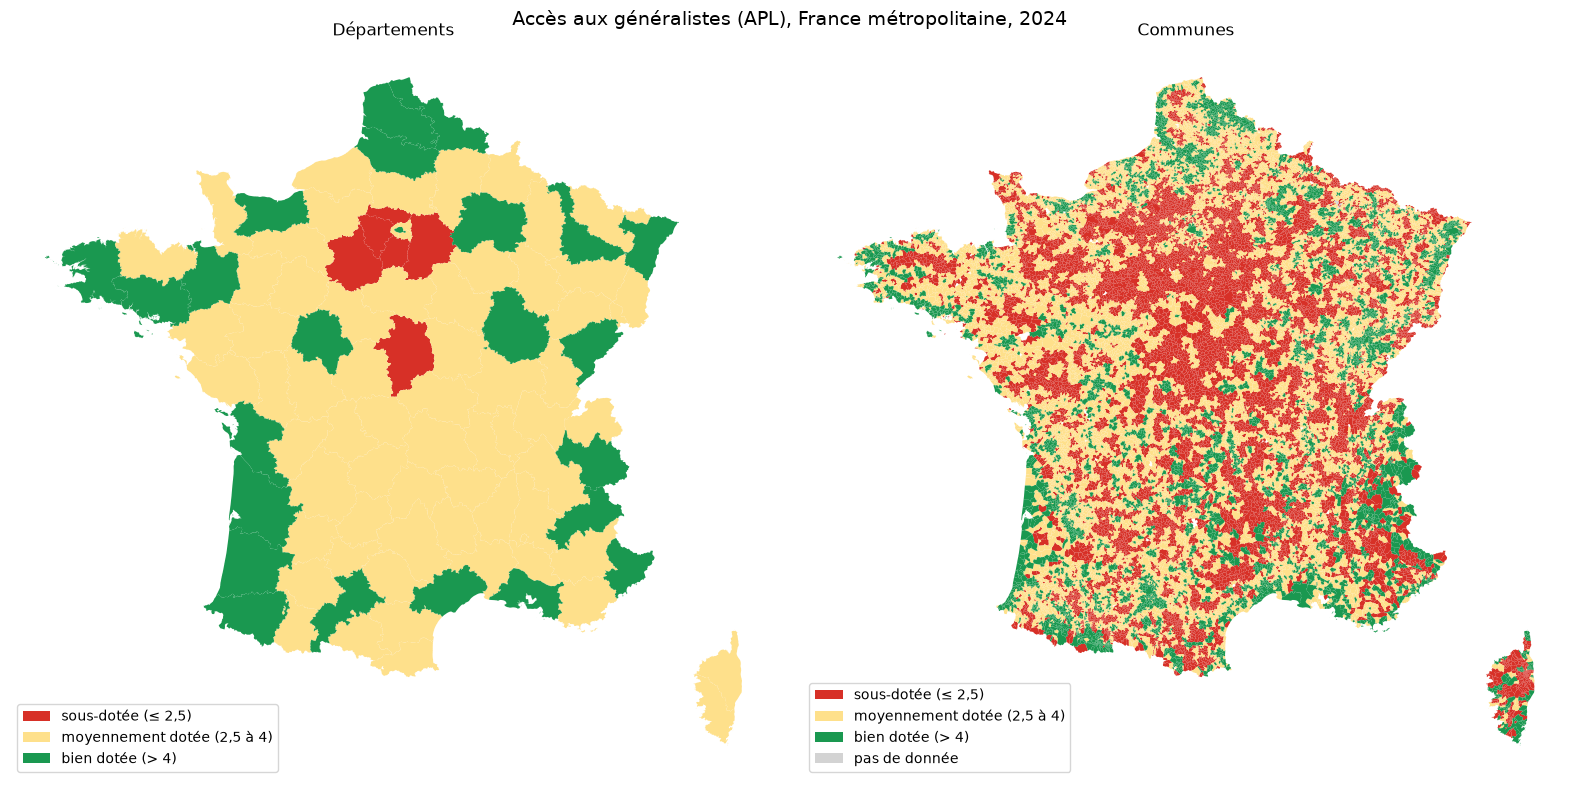

In [48]:
cote_a_cote("classe_apl", "Accès aux généralistes (APL), France métropolitaine, 2024",
            cmap=ListedColormap(["#d73027", "#fee08b", "#1a9850"]), categorie=True,
            fichier="../figures/apl_dep_commune.png")

À l'échelle départementale, la sous-dotation en généralistes (APL ≤ 2,5) ne concerne que six départements, regroupés autour du Bassin parisien (Seine-et-Marne, Essonne, Val-d'Oise, Yvelines, Eure-et-Loir) et le Cher ; la grande majorité des départements est moyennement dotée, et le Nord, le littoral atlantique et une partie du Sud-Est sont bien dotés. À l'échelle communale, le tableau est très différent : la sous-dotation forme de larges plages continues, y compris dans des départements classés « moyennement dotés » (intérieur de la Bretagne, Massif central, Corse). 

L'écart s'explique par la pondération : la moyenne départementale est tirée par les villes, mieux dotées, et masque les communes rurales sous-dotées. Cela laisse transparaitre le fait que la sous-dotation dépend de l'échelle, ce que la corrélation avec le niveau de vie devra confirmer.

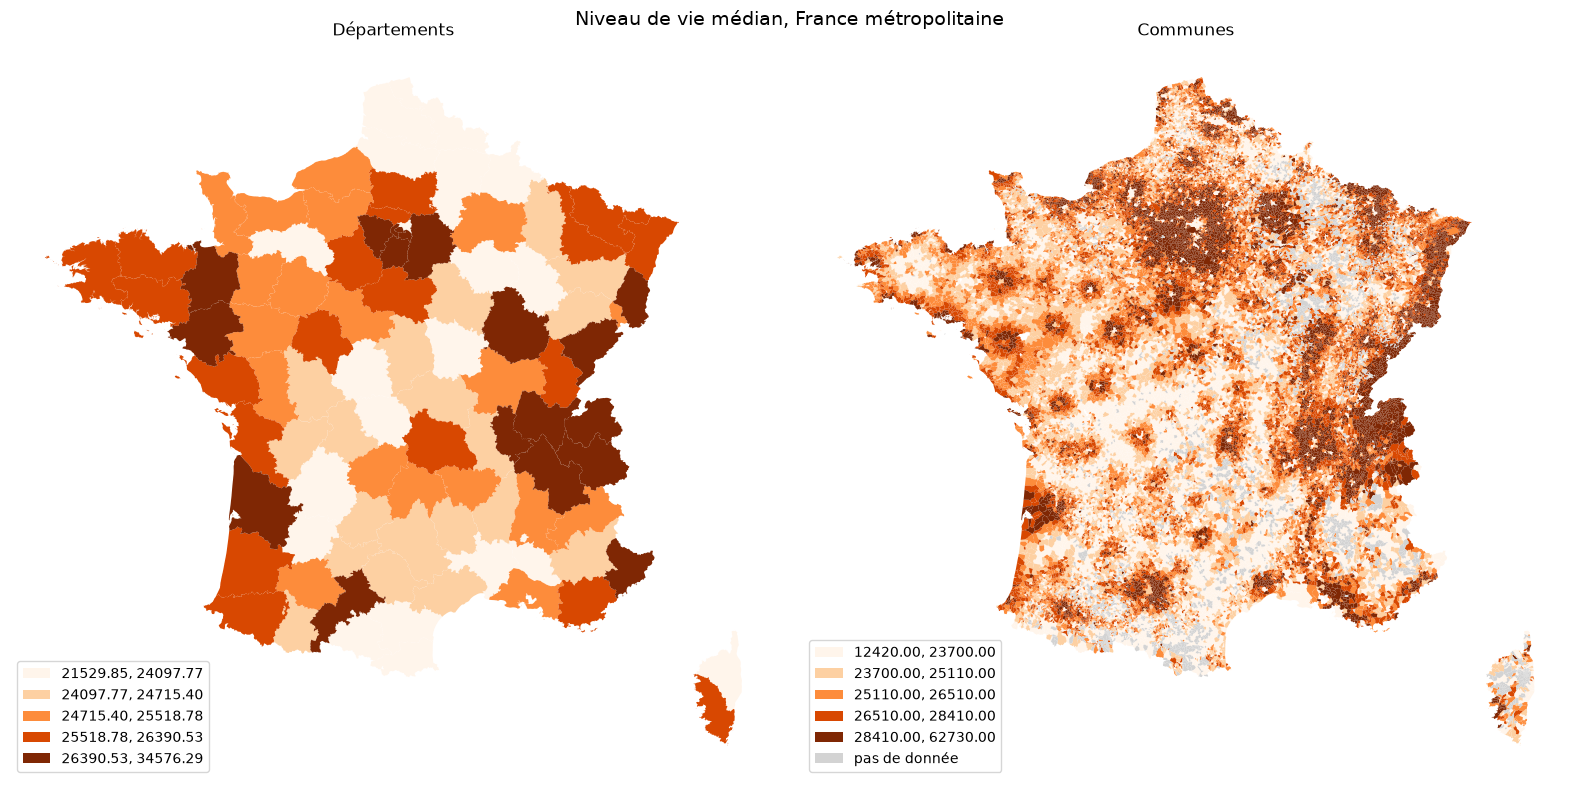

In [49]:
cote_a_cote("revenu_median", "Niveau de vie médian, France métropolitaine",
            cmap="Oranges", fichier="../figures/revenu_dep_commune.png")

À l'échelle départementale, le niveau de vie médian oppose les départements urbains et frontaliers (Île-de-France, Ouest urbain, Bordeaux, Toulouse, région lyonnaise, Alsace, Côte d'Azur) aux départements du Nord, du Centre et du Sud-Ouest rural, avec un rapport d'environ 1,6 entre les extrêmes. À l'échelle communale, la carte montre des halos aisés autour des grandes villes et des zones modestes dans les campagnes. La moyenne départementale masque de fortes inégalités internes. Les communes sans donnée sont situées dans les zones peu denses. 

## 7- Lien niveau de vie et APL

In [50]:
m = d.dropna(subset=["apl", "revenu_median"])
print("Communes :", round(m["apl"].corr(m["revenu_median"], method="spearman"), 3))
print("Départements :", round(dep["apl"].corr(dep["revenu_median"], method="spearman"), 3))

Communes : 0.094
Départements : 0.199


La correlation de Spearman entre l'APL et le revenu médian est positive mais très faible tant au niveau communal qu'au niveau départemental. Le niveau de vie n'explique donc pas à lui seul quasiment les différences d'accessibilité.

In [51]:
# Calcul du nombre d'hopitaux pour 100 000 habitants dans un département

# Hôpitaux, population et PIB : sommes / valeur unique par département
extra = (d.groupby("DEP")
           .agg(nb_hopitaux=("nb_hopitaux", "sum"),
                pop_tot=("pop_tot", "sum"),
                pib_hab=("pib_hab", "first"))
           .reset_index())
extra["hop_100k"] = extra["nb_hopitaux"] / extra["pop_tot"] * 100_000

# APL et revenu pondérés
dep = pd.DataFrame({
    "apl": moyenne_ponderee(d, "apl", "pop_std"),
    "revenu_median": moyenne_ponderee(d, "revenu_median", "pop_tot"),
}).reset_index().merge(extra, on="DEP", how="left")

print(dep.shape)
print(dep.head())

(96, 7)
  DEP       apl  revenu_median  nb_hopitaux   pop_tot  pib_hab  hop_100k
0  01  2.567869   29411.216221           19  671289.0  41949.0  2.830376
1  02  3.123365   23087.672827           19  525558.0  32891.0  3.615205
2  03  3.134498   24290.962623           13  334715.0  41949.0  3.883901
3  04  3.594819   24282.077085           14  167179.0  41818.0  8.374258
4  05  4.806879   25090.016239           10  141677.0  41818.0  7.058309


In [52]:
res = []
for riche in ["revenu_median", "pib_hab"]:
    for soin in ["apl", "hop_100k"]:
        b = dep.dropna(subset=[riche, soin])
        rho, p = spearmanr(b[riche], b[soin])
        res.append({"richesse": riche, "offre": soin, "rho": round(rho, 3), "p": round(p, 4), "n": len(b)})
print(pd.DataFrame(res))

        richesse     offre    rho       p   n
0  revenu_median       apl  0.199  0.0514  96
1  revenu_median  hop_100k -0.415  0.0000  96
2        pib_hab       apl  0.000  0.9977  96
3        pib_hab  hop_100k -0.313  0.0019  96


Le nombre d'hôpitaux rapporté à la population est corrélé négativement au revenu médian (ρ = -0,42 ; p < 0,001) et au PIB par habitant (ρ = -0,31 ; p = 0,002). Les départements les plus riches ne concentrent donc pas les hôpitaux, ils en comptent plutôt moins par habitant. L'APL, de son côté, n'est que faiblement liée au revenu médian (ρ = 0,20 ; p = 0,051) et indépendante du PIB par habitant (ρ = 0,00 ; p = 1,00).

## 8. Conclusion

Nous avons testé l'hypothèse selon laquelle les zones riches concentrent l'offre de soins à l'aide de corrélations de Spearman sur les 96 départements métropolitains, l'APL et le revenu médian étant des moyennes pondérées par la population.

Le nombre d'hôpitaux rapporté à la population est corrélé négativement au revenu médian (ρ = -0,42 ; p < 0,001) et au PIB par habitant (ρ = -0,31 ; p = 0,002). Les départements les plus riches ne concentrent donc pas les hôpitaux, ils en comptent plutôt moins par habitant. L'APL, de son côté, n'est que faiblement liée au revenu médian (ρ = 0,20 ; p = 0,051) et indépendante du PIB par habitant (ρ = 0,00 ; p = 1,00). À l'échelle des 30 770 communes, le lien entre revenu et APL est encore plus faible (ρ = 0,09).

Les cartes confirment ce résultat : les zones sous-dotées en généralistes ne correspondent ni aux territoires les plus pauvres ni aux plus riches.